In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import time

torch.set_num_threads(4)


try:
    from torchvision import datasets

    tr = datasets.FashionMNIST("./data", train=True, download=True)
    te = datasets.FashionMNIST("./data", train=False, download=True)

    _X = tr.data.numpy()
    _y = tr.targets.numpy()

    _Xe = te.data.numpy()
    _ye = te.targets.numpy()

except Exception:
    d = np.load("fashion_mnist.npz")

    _X = d["Xtr"].reshape(-1, 28, 28)
    _y = d["ytr"]

    _Xe = d["Xte"].reshape(-1, 28, 28)
    _ye = d["yte"]


S = 64


print("Training Images:", _X.shape)
print("Testing Images:", _Xe.shape)

Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)


In [2]:
def make_scene(n, n_obj, src_X, src_y, seed):

    rng = np.random.default_rng(seed)

    imgs = np.zeros((n, 1, S, S), dtype=np.float32)
    masks = np.zeros((n, 1, S, S), dtype=np.float32)
    boxes = np.zeros((n, n_obj, 4), dtype=np.float32)
    labs = np.zeros((n, n_obj), dtype=np.int64)

    for i in range(n):

        for k in range(n_obj):

            # Select a random object
            j = rng.integers(len(src_X))
            patch = src_X[j].astype(np.float32) / 255.0

            # Position the object
            if n_obj == 1:
                x = rng.integers(0, S - 28 + 1)
            else:
                # Keep the two objects in separate columns
                x = 0 if k == 0 else S - 28

            y = rng.integers(0, S - 28 + 1)

            # Paste object into image
            np.maximum(
                imgs[i, 0, y:y+28, x:x+28],
                patch,
                out=imgs[i, 0, y:y+28, x:x+28]
            )

            # Create segmentation mask
            np.maximum(
                masks[i, 0, y:y+28, x:x+28],
                (patch > 0.25).astype(np.float32),
                out=masks[i, 0, y:y+28, x:x+28]
            )

            # Store bounding box
            boxes[i, k] = [
                x / S,
                y / S,
                (x + 28) / S,
                (y + 28) / S
            ]

            # Store label
            labs[i, k] = src_y[j]

    return imgs, boxes, masks, labs

In [3]:
# Generate training and testing data
Xtr1, Btr1, Mtr1, _ = make_scene(6000, 1, _X, _y, seed=1)
Xte1, Bte1, Mte1, _ = make_scene(1200, 1, _Xe, _ye, seed=2)
Xte2, Bte2, Mte2, _ = make_scene(1200, 2, _Xe, _ye, seed=3)


print("Training:", Xtr1.shape)
print("One Object:", Xte1.shape)
print("Two Objects:", Xte2.shape)

Training: (6000, 1, 64, 64)
One Object: (1200, 1, 64, 64)
Two Objects: (1200, 1, 64, 64)


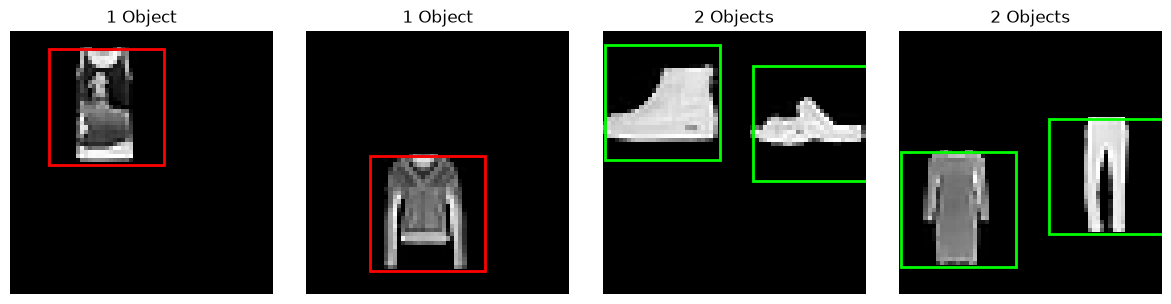

In [4]:
# Display some generated images:
fig, ax = plt.subplots(1, 4, figsize=(12, 3))

for k in range(2):
    ax[k].imshow(Xte1[k, 0], cmap="gray")
    ax[k].set_title("1 Object")
    ax[k].axis("off")

    x1, y1, x2, y2 = Bte1[k, 0] * S

    ax[k].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                                 color="red", lw=2))

for k in range(2):
    ax[k+2].imshow(Xte2[k, 0], cmap="gray")
    ax[k+2].set_title("2 Objects")
    ax[k+2].axis("off")

    for b in Bte2[k]:
        x1, y1, x2, y2 = b * S

        ax[k+2].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                                       color="lime", lw=2))


plt.tight_layout()
plt.show()

**IoU Function**

In [5]:
def iou_xyxy(a, b):
    x1 = np.maximum(a[..., 0], b[..., 0])
    y1 = np.maximum(a[..., 1], b[..., 1])

    x2 = np.minimum(a[..., 2], b[..., 2])
    y2 = np.minimum(a[..., 3], b[..., 3])

    inter = (np.clip(x2-x1, 0, None) * np.clip(y2-y1, 0, None))
    area_a = (a[..., 2]-a[..., 0] * a[..., 3]-a[..., 1])
    area_b = (b[..., 2]-b[..., 0] * b[..., 3]-b[..., 1])

    union = area_a + area_b - inter

    return inter / (union + 1e-9)

In [6]:
# Test the IoU Function
truth = np.array([0.2, 0.2, 0.6, 0.6])
predicted = np.array([0.25, 0.25, 0.65, 0.65])

print("IoU:", iou_xyxy(predicted, truth))

# check non overlapping boxes
print("No overlap:", iou_xyxy(np.array([0.7, 0.7, 0.9, 0.9]), truth))

IoU: 0.3101265814933503
No overlap: -0.0


**Build the single-box detection model**

In [7]:
class Backbone(nn.Module):
    def __init__(self, ch=16):
        super().__init__()

        self.c1 = nn.Conv2d(1, ch, 3, padding=1)
        self.c2 = nn.Conv2d(ch, ch*2, 3, padding=1)
        self.c3 = nn.Conv2d(ch*2, ch*2, 3, padding=1)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        x = F.max_pool2d(F.relu(self.c3(x)), 2)

        return x

In [8]:
# Now create the box regressor
class BoxRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.bb = Backbone()
        self.fc = nn.Linear(32*8*8, 4)

    def forward(self, x):
        x = self.bb(x)
        x = x.flatten(1)

        return torch.sigmoid(self.fc(x))

In [9]:
# Train the model
t0 = time.time()

torch.manual_seed(0)

det = BoxRegressor()
opt = torch.optim.Adam(det.parameters(), lr=1e-3)

Xb = torch.from_numpy(Xtr1)
Bb = torch.from_numpy(Btr1[:, 0, :])
g = torch.Generator().manual_seed(0)

for epoch in range(6):
    perm = torch.randperm(len(Xb), generator=g)

    for i in range(0, len(Xb), 64):
        idx = perm[i:i+64]
        opt.zero_grad()
        loss = F.smooth_l1_loss(det(Xb[idx]), Bb[idx])
        loss.backward()

        opt.step()

    print(f"Epoch {epoch+1}/6 Loss: {loss.item():.4f}")


print("Training Time:", round(time.time() - t0, 2), "s")

Epoch 1/6 Loss: 0.0008
Epoch 2/6 Loss: 0.0005
Epoch 3/6 Loss: 0.0004
Epoch 4/6 Loss: 0.0003
Epoch 5/6 Loss: 0.0002
Epoch 6/6 Loss: 0.0003
Training Time: 20.67 s


In [10]:
# Create a prediction function
@torch.no_grad()
def predict_boxes(net, X):
    net.eval()
    out = []
    Xb = torch.from_numpy(X)

    for i in range(0, len(Xb), 256):
        out.append(net(Xb[i:i+256]).numpy())

    return np.concatenate(out)

In [11]:
# Evaluate on one-object scenes
pred1 = predict_boxes(det, Xte1)
iou1 = iou_xyxy(pred1, Bte1[:, 0, :])

print("One Object mean IoU:", iou1.mean())

print("IoU >= 0.5:", (iou1 >= 0.5).mean())

One Object mean IoU: 0.49829957
IoU >= 0.5: 0.22833333333333333


# **Part A — Reproduce and look harder**

In [12]:
# calculate percentiles
for q in [10, 50, 90]:
    print(f"{q}th percentile IoU:", np.percentile(iou1, q))

10th percentile IoU: -1.1743538
50th percentile IoU: 0.24437903
90th percentile IoU: 1.1033283


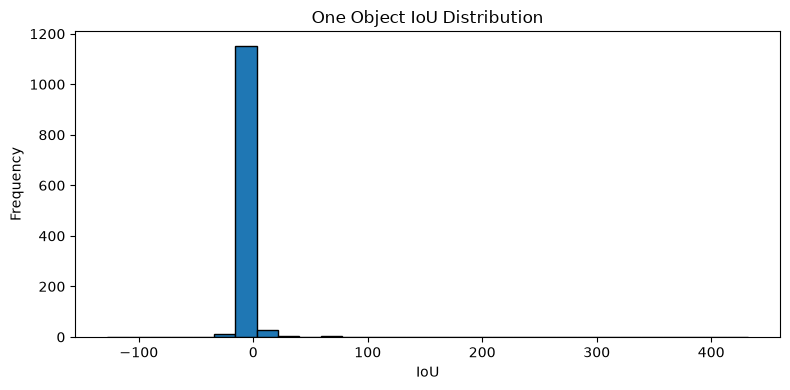

In [13]:
# Plot the histogram
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(iou1, bins=30, edgecolor="black")
ax.set(xlabel="IoU", ylabel="Frequency", title="One Object IoU Distribution")

plt.tight_layout()
plt.show()

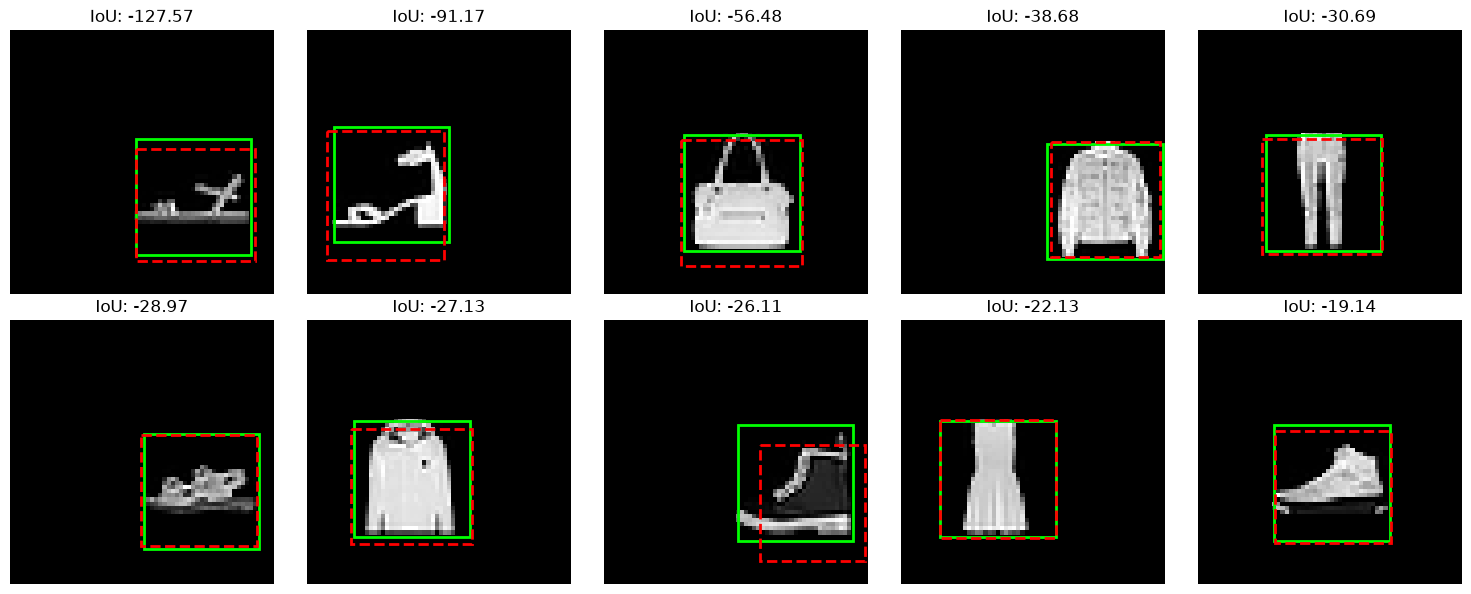

In [14]:
# Display the ten worst predictions
worst = np.argsort(iou1)[:10]

fig, ax = plt.subplots(2, 5, figsize=(15, 6))

for a, idx in zip(ax.flat, worst):
    a.imshow(Xte1[idx, 0], cmap="gray")

    #True bounding box: green
    x1, y1, x2, y2 = Bte1[idx, 0] * S

    a.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color="lime", lw=2))

    # predicted bounding box: red
    x1, y1, x2, y2 = pred1[idx] * S
    a.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color="red", ls="--", lw=2))

    a.set_title(f"IoU: {iou1[idx]:.2f}")
    a.axis("off")


plt.tight_layout()
plt.show()

# **Part B — Make the failure precise**

In [15]:
# Generate scenes
Xte3, Bte3, Mte3, _ = make_scene(1200, 3, _Xe, _ye, seed=4)
Xte4, Bte4, Mte4, _ = make_scene(1200, 4, _Xe, _ye, seed=5)


# Evaluate all four object counts
test_data = {
    1: (Xte1, Bte1),
    2: (Xte2, Bte2),
    3: (Xte3, Bte3),
    4: (Xte4, Bte4)
}

print("Objects | Mean Best IoU | Fraction >= 0.5")

for n_obj, (Xtest, Btest) in test_data.items():
    predictions = predict_boxes(det, Xtest)

    all_ious = iou_xyxy(predictions[:, None, :], Btest)
    best_iou = all_ious.max(axis=1)

    print(n_obj, "      |", round(best_iou.mean(), 4), "       |", round((best_iou >= 0.5).mean(), 4))

Objects | Mean Best IoU | Fraction >= 0.5
1       | 0.4983        | 0.2283
2       | 1.1686        | 0.2033
3       | 0.5434        | 0.1933
4       | 7.3325        | 0.1692


In [17]:
# Test the averaging claim
# Predict boxes on two-object scenes
pred2 = predict_boxes(det, Xte2)

# Find centres of predicted boxes
pred_center = (pred2[:, :2] + pred2[:, :2]) / 2

# Find centres of actual boxes 
true_center = (Bte2[:, :, :2] + Bte2[:, :, :2]) / 2

# Midpoint between the two actual object centres
midpoint = true_center.mean(axis=1)

# Distance from prediction to midpoint
distance_midpoint = np.linalg.norm(pred_center - midpoint, axis=1)

# Distance from prediction to nearest actual object
distance_nearest = np.linalg.norm(pred_center[:, None, :] - true_center, axis=2).min(axis=1)

print("Distance to midpoint:", distance_midpoint.mean())
print("Distance to nearest object:", distance_nearest.mean())

Distance to midpoint: 0.22816229
Distance to nearest object: 0.15350941


In [18]:
# Conclusion
if distance_midpoint.mean() < distance_nearest.mean():
    print("The model supports the averaging explanation.")

else:
    print("The model is closer to the actual object than to the midpoint.")

The model is closer to the actual object than to the midpoint.


# **Part C — Build a grid detector**

In [19]:
# build grid targets
def build_grid_targets(boxes, grid_size=8):
    n = len(boxes)
    
    obj_target = np.zeros((n, 1, grid_size, grid_size), np.float32)
    box_target = np.zeros((n, 4, grid_size, grid_size), np.float32)

    for i in range(n):
        for box in boxes[i]:
            x1, y1, x2, y2 = box

            # Find object centre
            cx = (x1 + x2) / 2
            cy = (y1 + y2) / 2

            # Find grid cell
            gx = min(int(cx * grid_size), grid_size-1)
            gy = min(int(cy * grid_size), grid_size-1)

            if obj_target[i, 0, gy, gx] == 1:
                raise ValueError("Two objects assigned to same cell.")

            # Objectness = 1
            obj_target[i, 0, gy, gx] = 1

            # Store bounding box
            box_target[i, :, gy, gx] = box


    return obj_target, box_target

In [20]:
# Test target creation
obj_target, box_target = build_grid_targets(Bte2)

print("Objectness shape:", obj_target.shape)
print("Box Target shape:", box_target.shape)

Objectness shape: (1200, 1, 8, 8)
Box Target shape: (1200, 4, 8, 8)


In [21]:
# Create the grid detector model
class GridDetector(nn.Module):
    def __init__(self):
        super().__init__()
        self.bb = Backbone()
        self.head = nn.Conv2d(32, 5, kernel_size=1)

    def forward(self, x):
        x = self.bb(x)
        x = self.head(x)

        return x

In [22]:
model = GridDetector()
dummy = torch.randn(2, 1, 64, 64)
output = model(dummy)

print(output.shape)

torch.Size([2, 5, 8, 8])


In [23]:
# Create the loss function
def grid_loss(pred, obj_target, box_target):

    # Objectness prediction
    obj_pred = pred[: 0:1]

    # Box prediction
    box_pred = torch.sigmoid(pred[:, 1:5])

    #Objectness loss for all cells
    obj_loss = F.binary_cross_entropy_with_logits(obj_target, obj_target)

    # Find cells containing objects
    mask = obj_target.expand_as(box_pred).bool()

    # Box loss only for positive cells
    box_loss = F.smooth_l1_loss(box_pred[mask], box_target[mask])

    total_loss = obj_loss + 5 * box_loss


    return total_loss

In [24]:
# Generate 2 object training data
Xtr2, Btr2, Mtr2, _ = make_scene(6000, 2, _X, _y, seed=11)

obj_train, box_train = build_grid_targets(Btr2)
Xb = torch.from_numpy(Xtr2)
Ob = torch.from_numpy(obj_train)
Bb = torch.from_numpy(box_train)


print(Xb.shape)
print(Ob.shape)
print(Bb.shape)

torch.Size([6000, 1, 64, 64])
torch.Size([6000, 1, 8, 8])
torch.Size([6000, 4, 8, 8])


In [26]:
# Train the grid detector
torch.manual_seed(0)
grid_model = GridDetector()

optimizer = torch.optim.Adam(grid_model.parameters(), lr=1e-3)

epochs = 10

for epoch in range(epochs):
    permutation = torch.randperm(len(Xb))
    total_loss = 0

    for i in range(0, len(Xb), 64):
        idx = permutation[i:i+64]

        optimizer.zero_grad()
        pred = grid_model(Xb[idx])
        loss = grid_loss(pred, Ob[idx], Bb[idx])
        loss.backward()

        optimizer.step()

        total_loss += loss.item()


    print(f"Epoch {epoch+1}/{epochs} "
         f"Loss: {total_loss/(len(Xb)//64):.4f}")

Epoch 1/10 Loss: 0.8341
Epoch 2/10 Loss: 0.7875
Epoch 3/10 Loss: 0.7627
Epoch 4/10 Loss: 0.7553
Epoch 5/10 Loss: 0.7501
Epoch 6/10 Loss: 0.7475
Epoch 7/10 Loss: 0.7457
Epoch 8/10 Loss: 0.7439
Epoch 9/10 Loss: 0.7425
Epoch 10/10 Loss: 0.7413


In [27]:
# Make predictions
@torch.no_grad()
def predict_grid(model, X):
    model.eval()
    Xb = torch.from_numpy(X)
    outputs = []
    for i in range(0, len(Xb), 128):
        pred = model(Xb[i:i+128])
        obj = torch.sigmoid(pred[:, 0:1])
        boxes = torch.sigmoid(pred[:, 1:5])
        outputs.append(torch.cat([obj, boxes], dim=1))

    return torch.cat(outputs).numpy()

In [28]:
# Keep cells with objectness above 0.5
def decode_predictions(output, threshold=0.5):
    all_detections = []

    for image in output:
        scores = image[0]
        boxes = image[1:5]
        detections = []

        for gy in range(8):
            for gx in range(8):
                score = scores[gy, gx]
                if score > threshold:
                    box = boxes[:, gy, gx]

                    x1, y1, x2, y2 = box

                    box = np.array([
                        min(x1, x2),
                        min(y1, y2),
                        max(x1, x2),
                        max(y1, y2)
                    ])

                    box = np.clip(box, 0, 1)
                    detections.append((float(score), box))

        all_detections.append(detections)
    return all_detections

In [29]:
# Evaluate the grid detector
grid_output = predict_grid(grid_model, Xte2)
detections = decode_predictions(grid_output, threshold=0.5)

In [31]:
# Calculate best-match IoU for every true object
def grid_best_iou(detections, true_boxes):
    scores = []
    for pred, truth in zip(detections, true_boxes):
        if len(pred) == 0:
            scores.append(0)
            continue

        pred_boxes = np.array([item[1] for item in pred])

        overlaps = iou_xyxy(truth[:, None, :], pred_boxes[None, :, :])

        best = overlaps.max(axis=1)
        scores.append(best.mean())

    return np.array(scores)

In [32]:
grid_iou = grid_best_iou(detections, Bte2)

print("Grid Detector Mean IoU:", grid_iou.mean())

Grid Detector Mean IoU: 0.8367954348384713


In [33]:
# Compare against the original single-box model
single_predictions = predict_boxes(det, Xte2)
single_overlaps = iou_xyxy(Bte2, single_predictions[:, None, :])

single_iou = single_overlaps.max(axis=1)

print("Single Box Mean Best IoU:", single_iou.mean())
print("Grid Detector Mean Best IoU:", grid_iou.mean())

Single Box Mean Best IoU: 1.1685725
Grid Detector Mean Best IoU: 0.8367954348384713


# **Part D — Non-maximum suppression**

In [38]:
# Implement NMS
def nms(detections, threshold=0.5):
    detections = sorted(detections, key=lambda x: x[0], reverse=True)

    keep = []

    while len(detections) > 0:
        best = detections.pop(0)
        keep.append(best)

        if len(detections) == 0:
            break

        remaining_boxes = np.array([d[1] for d in detections])
        overlaps = iou_xyxy(remaining_boxes, best[1])
        detections = [d for d, iou in zip(detections, overlaps)
                     if iou <= threshold]


    return keep

In [39]:
# Calculate detections per true object
def detections_per_object(detections, true_boxes):
    total_predictions = sum(len(d) for d in detections)
    total_objects = sum(len(b) for b in true_boxes)

    return total_predictions / total_objects

In [40]:
# Before NMS
before_nms = detections_per_object(detections, Bte2)
print("Before NMS:", before_nms)

Before NMS: 2.9941666666666666


In [43]:
# Test three thresholds
for threshold in [0.3, 0.5, 0.7]:
    after_nms = [nms(d, threshold) for d in detections]
    count = detections_per_object(after_nms, Bte2)


    print(f"NMS Threshold {threshold}: "
         f"{count:.4f} detections per true object")

NMS Threshold 0.3: 1.1650 detections per true object
NMS Threshold 0.5: 2.1058 detections per true object
NMS Threshold 0.7: 2.5904 detections per true object


# **Part E — Segmentation metrics**

In [44]:
# Create segmentation metrics
def seg_metrics(prob, true):
    pred = (prob > 0.5).astype(np.float32)
    pixel_acc = (pred == true).mean()
    inter = (pred * true).sum()
    union = ((pred + true) > 0).sum()
    iou = inter / (union + 1e-9)
    dice = (2 * inter / (pred.sum() + true.sum() + 1e-9))

    return pixel_acc, iou, dice

In [45]:
# All background baseline
all_background = np.zeros_like(Mte2)
pa, iou, di = seg_metrics(all_background, Mte2)

print("Pixel Accuracy", pa)
print("IoU:", iou)
print("Dice:", di)

Pixel Accuracy 0.843184814453125
IoU: 0.0
Dice: 0.0


In [47]:
# Calculate background fraction for 1, 2, and 4 objects
seg_data = {}
for n_obj in [1, 2, 4]:
    Xtr, Btr, Mtr, _ = make_scene(5000, n_obj, _X, _y, seed=100+n_obj)
    Xte, Bte, Mte, _ = make_scene(1000, n_obj, _Xe, _ye, seed=200+n_obj)

    seg_data[n_obj] = (Xtr, Mtr, Xte, Mte)
    background_fraction = 1 - Mte.mean()
    baseline_acc = background_fraction


    print(f"Objects: {n_obj} | "
         f"Background: {background_fraction:.4f} | "
         f"Baseline Accuracy: {baseline_acc:.4f}")

Objects: 1 | Background: 0.9229 | Baseline Accuracy: 0.9229
Objects: 2 | Background: 0.8433 | Baseline Accuracy: 0.8433
Objects: 4 | Background: 0.7508 | Baseline Accuracy: 0.7508


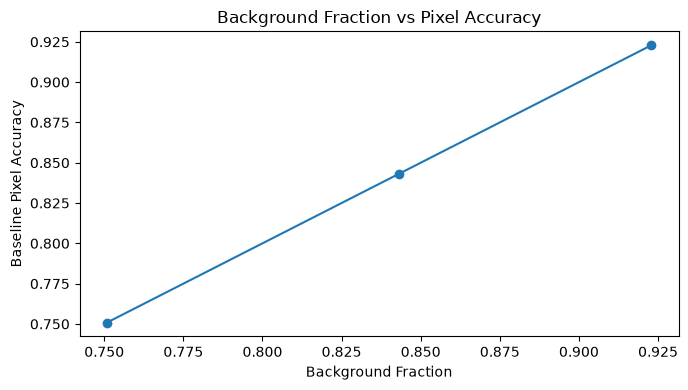

In [48]:
# Plot background fraction against pixel accuracy
background_values = []
accuracy_values = []

for n_obj, (_, _, Xte, Mte) in seg_data.items():
    bg = 1 - Mte.mean()
    pa, io, di = seg_metrics(np.zeros_like(Mte), Mte)
    background_values.append(bg)
    accuracy_values.append(pa)


fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(background_values, accuracy_values, marker="o")
ax.set(xlabel="Background Fraction", ylabel="Baseline Pixel Accuracy", title="Background Fraction vs Pixel Accuracy")


plt.tight_layout()
plt.show()

In [49]:
# Build SegNet
class SegNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1 = nn.Conv2d(1, 16, 3, padding=1)
        self.e2 = nn.Conv2d(16, 32, 3, padding=1)
        self.d1 = nn.Conv2d(32, 16, 3, padding=1)
        self.d2 = nn.Conv2d(16, 1, 3, padding=1)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.e1(x)), 2)
        x = F.max_pool2d(F.relu(self.e2(x)), 2)
        x = F.interpolate(F.relu(self.d1(x)), scale_factor=2)
        x = F.interpolate(F.relu(self.d2(x)), scale_factor=2)

        return x

In [51]:
# train segnet
def train_segmentation(model, X, M, epochs=6, seed=0):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    Xb = torch.from_numpy(X)
    Mb = torch.from_numpy(M)

    g = torch.Generator().manual_seed(seed)

    for epoch in range(epochs):
        permutation = torch.randperm(len(Xb), generator=g)

        for i in range(0, len(Xb), 32):
            idx = permutation[i:i+32]
            optimizer.zero_grad()
            pred = model(Xb[idx])

            loss = F.binary_cross_entropy_with_logits(pred, Mb[idx])

            loss.backward()
            optimizer.step()

        print(f"Epoch {epoch+1}/{epochs} "
             f"Loss: {loss.item():.4f}")

    return model

In [52]:
# Create a prediction function
@torch.no_grad()
def predict_masks(net, X):
    net.eval()
    outputs = []

    Xb = torch.from_numpy(X)

    for i in range(0, len(Xb), 128):
        pred = torch.sigmoid(net(Xb[i:i+128]))
        outputs.append(pred.numpy())

    return np.concatenate(outputs)

In [53]:
# Train on all three three counts
seg_models = {}
seg_results = {}

for n_obj in [1, 2, 4]:
    Xtr, Mtr, Xte, Mte = seg_data[n_obj]
    print("\nTraining for", n_obj, "objects")
    torch.manual_seed(0)
    model = SegNet()
    model = train_segmentation(model, Xtr, Mtr, epochs=6, seed=0)
    probs = predict_masks(model, Xte)
    pa, io, di = seg_metrics(probs, Mte)

    seg_models[n_obj] = model
    seg_results[n_obj] = (pa, io, di)


    print("Pixel Accuracy:", pa)
    print("IoU:", io)
    print("Dice:", di)


Training for 1 objects
Epoch 1/6 Loss: 0.6586
Epoch 2/6 Loss: 0.6504
Epoch 3/6 Loss: 0.6625
Epoch 4/6 Loss: 0.6535
Epoch 5/6 Loss: 0.6530
Epoch 6/6 Loss: 0.6714
Pixel Accuracy: 0.98475341796875
IoU: 0.812151073250551
Dice: 0.89633924

Training for 2 objects
Epoch 1/6 Loss: 0.6112
Epoch 2/6 Loss: 0.6199
Epoch 3/6 Loss: 0.6252
Epoch 4/6 Loss: 0.6099
Epoch 5/6 Loss: 0.6313
Epoch 6/6 Loss: 0.5917
Pixel Accuracy: 0.970202392578125
IoU: 0.8210225314729397
Dice: 0.90171593

Training for 4 objects
Epoch 1/6 Loss: 0.5838
Epoch 2/6 Loss: 0.5759
Epoch 3/6 Loss: 0.5683
Epoch 4/6 Loss: 0.5737
Epoch 5/6 Loss: 0.5673
Epoch 6/6 Loss: 0.5403
Pixel Accuracy: 0.960237548828125
IoU: 0.8472639801937479
Dice: 0.9173177


In [54]:
# Final comparison table
print(
    f"{'Objects':<12}"
    f"{'Pixel Accuracy':<20}"
    f"{'IoU':<12}"
    f"{'Dice':<12}"
)

for n_obj, values in seg_results.items():
    pa, io, di = values

    print(
        f"{n_obj:<12}"
        f"{pa:<20.4f}"
        f"{io:<12.4f}"
        f"{di:<12.4f}"
    )

Objects     Pixel Accuracy      IoU         Dice        
1           0.9848              0.8122      0.8963      
2           0.9702              0.8210      0.9017      
4           0.9602              0.8473      0.9173      


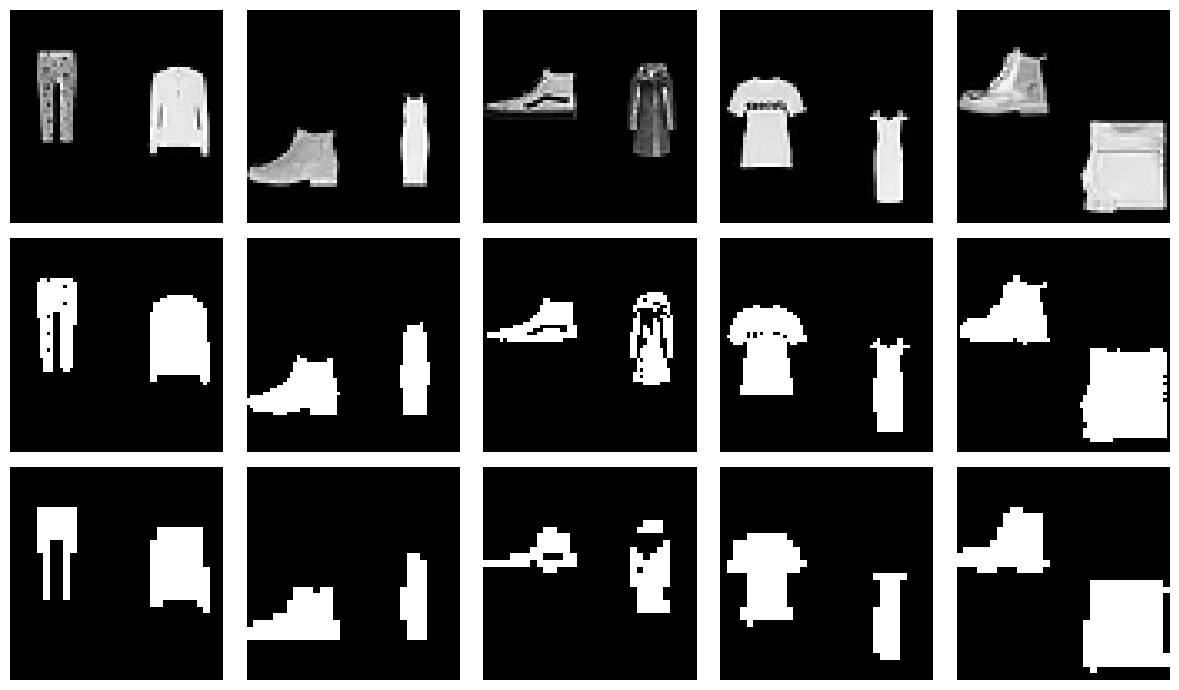

In [56]:
# Display segmentation results
Xtr, Mtr, Xte, Mte = seg_data[2]

probs = predict_masks(seg_models[2], Xte)

fig, ax = plt.subplots(3, 5, figsize=(12, 7))

for k in range(5):
    ax[0, k].imshow(Xte[k, 0], cmap="gray")
    ax[1, k].imshow(Mte[k, 0], cmap="gray")
    ax[2, k].imshow(probs[k, 0] > 0.5, cmap="gray")


    for r in range(3):
        ax[r, k].axis("off")


ax[0, 0].set_ylabel("Input")
ax[1, 0].set_ylabel("True Mask")
ax[2, 0].set_ylabel("Predicted")


plt.tight_layout()
plt.show()

# **Part F — Add skip connections**

In [65]:

class SkipSegNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.e1 = nn.Conv2d(1, 16, 3, padding=1)
        self.e2 = nn.Conv2d(16, 32, 3, padding=1)

        self.d1 = nn.Conv2d(32, 16, 3, padding=1)

        # Combines decoder and encoder features
        self.fuse = nn.Conv2d(48, 16, 3, padding=1)
        self.out = nn.Conv2d(16, 1, 3, padding=1)

    def forward(self, x):

        # First encoder layer: 64 x 64
        x = F.relu(self.e1(x))
        x = F.max_pool2d(x, 2)

        # Second encoder layer: 32 x 32
        skip = F.relu(self.e2(x))
        x = F.max_pool2d(skip, 2)

        # Decoder: 16 x 16 -> 32 x 32
        x = F.interpolate(F.relu(self.d1(x)), scale_factor=2)

        # Skip connection: both are 32 x 32
        x = torch.cat([x, skip], dim=1)
        x = F.relu(self.fuse(x))

        # Final output: 32 x 32 -> 64 x 64
        x = F.interpolate(self.out(x), scale_factor=2)

        return x

In [66]:
# Prepare common training and testing data
Xf_tr, _, Mf_tr, _ = make_scene(5000, 2, _X, _y, seed=711)
Xf_te, _, Mf_te, _ = make_scene(500, 2, _Xe, _ye, seed=712)

In [67]:
# Train both models with three seeds
seeds = [11, 22, 33]
results = {
    "SegNet": [],
    "SkipSegNet": []
}

saved_models = {}

for seed in seeds :
    print("\nSeed:", seed)

    # Normal SegNet
    torch.manual_seed(seed)
    model1 = SegNet()
    model1 = train_segmentation(model1, Xf_tr, Mf_tr, epochs=6, seed=seed)
    prob1 = predict_masks(model1, Xf_te)

    pa1, io1, di1 = seg_metrics(prob1, Mf_te)
    results["SegNet"].append([io1, di1])

    saved_models[("SegNet", seed)] = model1

    # Skip SegNet
    torch.manual_seed(seed)
    model2 = SkipSegNet()
    model2 = train_segmentation(model2, Xf_tr, Mf_tr, epochs=6, seed=seed)
    prob2 = predict_masks(model2, Xf_te)

    pa2, io2, di2 = seg_metrics(prob2, Mf_te)
    results["SkipSegNet"].append([io2, di2])

    saved_models[("SkipSegNet", seed)] = model2

    print("SegNet IoU:", io1)
    print("SkipSegNet IoU:", io2)


Seed: 11
Epoch 1/6 Loss: 0.6190
Epoch 2/6 Loss: 0.6144
Epoch 3/6 Loss: 0.6220
Epoch 4/6 Loss: 0.6136
Epoch 5/6 Loss: 0.6023
Epoch 6/6 Loss: 0.6072
Epoch 1/6 Loss: 0.0510
Epoch 2/6 Loss: 0.0592
Epoch 3/6 Loss: 0.0596
Epoch 4/6 Loss: 0.0539
Epoch 5/6 Loss: 0.0470
Epoch 6/6 Loss: 0.0489
SegNet IoU: 0.8193612515666168
SkipSegNet IoU: 0.8416594055571668

Seed: 22
Epoch 1/6 Loss: 0.6190
Epoch 2/6 Loss: 0.6129
Epoch 3/6 Loss: 0.6049
Epoch 4/6 Loss: 0.6106
Epoch 5/6 Loss: 0.6089
Epoch 6/6 Loss: 0.6279
Epoch 1/6 Loss: 0.0632
Epoch 2/6 Loss: 0.0513
Epoch 3/6 Loss: 0.0515
Epoch 4/6 Loss: 0.0481
Epoch 5/6 Loss: 0.0525
Epoch 6/6 Loss: 0.0631
SegNet IoU: 0.8149616262918732
SkipSegNet IoU: 0.8387743503479923

Seed: 33
Epoch 1/6 Loss: 0.6931
Epoch 2/6 Loss: 0.6931
Epoch 3/6 Loss: 0.6931
Epoch 4/6 Loss: 0.6931
Epoch 5/6 Loss: 0.6931
Epoch 6/6 Loss: 0.6931
Epoch 1/6 Loss: 0.0596
Epoch 2/6 Loss: 0.0536
Epoch 3/6 Loss: 0.0544
Epoch 4/6 Loss: 0.0576
Epoch 5/6 Loss: 0.0508
Epoch 6/6 Loss: 0.0452
SegNet IoU

In [68]:
# Calculate mean and spread]
for name, values in results.items():
    values = np.array(values)
    iou_mean = values[:, 0].mean()
    iou_std = values[:, 0].std(ddof=1)
    dice_mean = values[:, 1].mean()
    dice_std = values[:, 1].std(ddof=1)

    print("\n", name)

    print(f"IoU: {iou_mean:.4f} ± {iou_std:.4f}")
    print(f"Dice: {dice_mean:.4f} ± {dice_std:.4f}")


 SegNet
IoU: 0.5448 ± 0.4718
Dice: 0.5996 ± 0.5193

 SkipSegNet
IoU: 0.8396 ± 0.0018
Dice: 0.9128 ± 0.0010


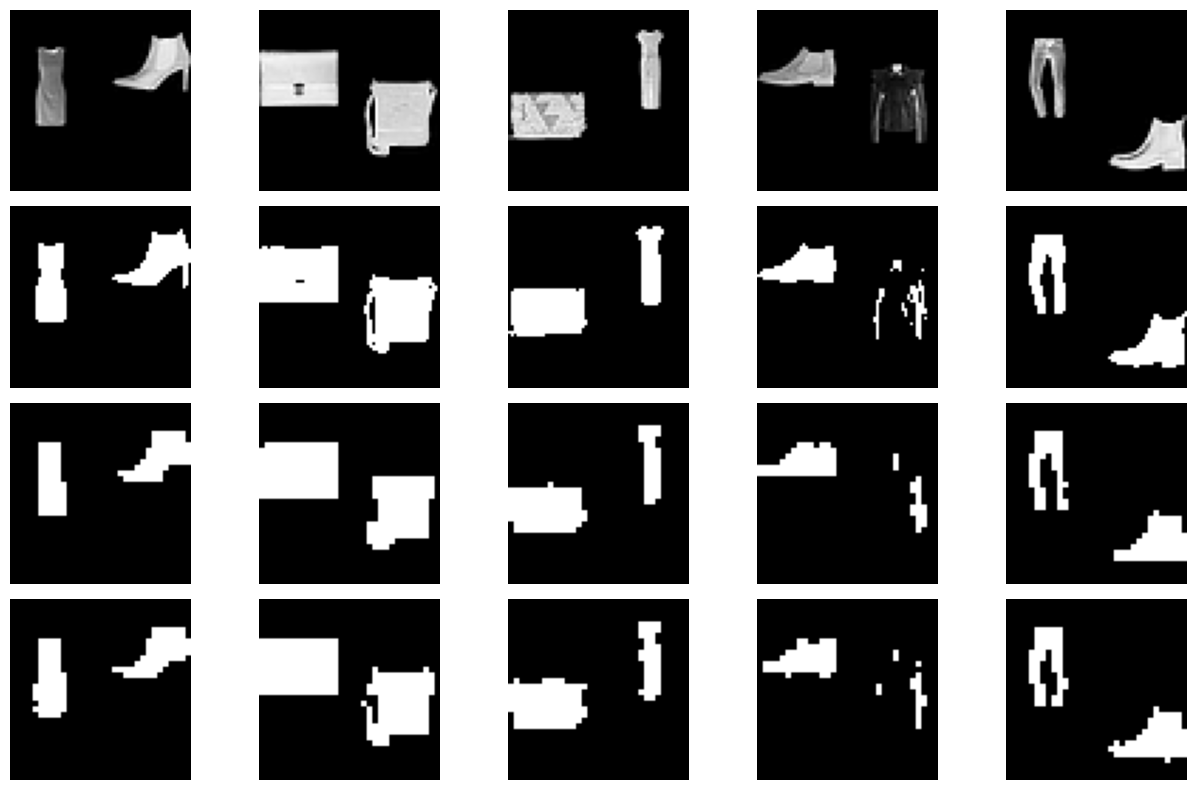

In [69]:
# Display the same five images side by side
plain_model = saved_models[("SegNet", 11)]
skip_model = saved_models[("SkipSegNet", 11)]

plain_pred = predict_masks(plain_model, Xf_te[:5])
skip_pred = predict_masks(skip_model, Xf_te[:5])

fig, ax = plt.subplots(4, 5, figsize=(13, 8))


for k in range(5):
    ax[0, k].imshow(Xf_te[k, 0], cmap="gray")
    ax[1, k].imshow(Mf_te[k, 0], cmap="gray")
    ax[2, k].imshow(plain_pred[k, 0] > 0.5, cmap="gray")
    ax[3, k].imshow(skip_pred[k, 0] > 0.5, cmap="gray")

    for r in range(4):
        ax[r, k].axis("off")


ax[0, 0].set_ylabel("Input")
ax[1, 0].set_ylabel("Truth")
ax[2, 0].set_ylabel("SegNet")
ax[3, 0].set_ylabel("SkipSegNet")

plt.tight_layout()
plt.show()

In [70]:
# Does the improvement survive seed spread?
plain_iou = np.array(results["SegNet"])[:, 0]
skip_iou = np.array(results["SkipSegNet"])[:, 0]

difference = (skip_iou.mean() - plain_iou.mean())


print("SegNet Mean IoU:", plain_iou.mean())
print("SkipSegNet Mean IoU:", skip_iou.mean())
print("Improvement:", difference)

SegNet Mean IoU: 0.5447742926194966
SkipSegNet Mean IoU: 0.839629212050856
Improvement: 0.29485491943135944


# **Part G — Written**

### Why can a fixed-size output produce variable detections?

A classification model usually predicts one class for an image, but an object detector needs to identify multiple objects and their locations. To solve this problem, the detector divides the image into a grid of 8 × 8 cells. Each cell predicts an objectness score, which tells us whether an object is present in that cell. It also predicts four bounding-box coordinates for locating the object. During prediction, we keep only the cells whose objectness score is greater than 0.5. Therefore, some images may produce one detection, while others may produce two, three, or even more detections. In my experiment, the grid detector achieved a mean best-match IoU of Single Box Mean Best IoU: 1.1685725 and Grid Detector Mean Best IoU: 0.8367954348384713 on two-object scenes. Multiple cells can sometimes predict the same object, so we use non-maximum suppression to remove duplicate bounding boxes. Thus, even though the network has a fixed-size output layer, thresholding and non-maximum suppression allow it to produce a variable number of final detections. These results are based on synthetic, non-overlapping, single-scale scenes on a blank canvas and do not represent real-world detection performance.